In [1]:
import sys, platform, datetime
import pandas, sklearn
sys.path.insert(0, '../src')  # para importar comun.py
print('Ejecutado el:', datetime.datetime.now().strftime('%d/%m/%Y %H:%M:%S'))
print('Python', platform.python_version(), '| pandas', pandas.__version__,
      '| scikit-learn', sklearn.__version__, '|', platform.system(), platform.release())


Ejecutado el: 22/10/2026 20:56:13
Python 3.13.7 | pandas 3.0.6 | scikit-learn 1.9.1 | Windows 11


# Tarea 4.1 · Validación del sistema y métricas de precisión y eficiencia

Se evalúa el sistema completo sobre la **presentación 2014J**, que el modelo nunca vio
durante el entrenamiento (validación temporal). Se responden cinco preguntas:

1. ¿Qué tan preciso es el diagnóstico de riesgo en cada momento del curso?
2. ¿Con cuánta anticipación detecta el sistema a quienes abandonan?
3. ¿Los perfiles diagnosticados corresponden a resultados reales distintos?
4. ¿Qué tan acertadas son las recomendaciones de ruta (misiones)?
5. ¿El ajuste de dificultad es coherente y estable? ¿Qué tan eficiente es el sistema?

Este archivo se puede ejecutar como script (`python 07_validacion.py`) o abrir como
notebook: `notebooks/validacion_sistema.ipynb` tiene exactamente las mismas celdas.

In [2]:
import json
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

from comun import CLAVE, CORTE_PRINCIPAL, DIR_FIGURAS, DIR_PROC, DIR_SALIDAS, PRESENTACION_PRUEBA

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
inst = pd.read_pickle(DIR_PROC / "rutas.pkl")
mon = pd.read_pickle(DIR_PROC / "monitoreo_semanal.pkl")
tray = pd.read_pickle(DIR_PROC / "trayectorias.pkl")
est = pd.read_pickle(DIR_PROC / "estudiantes.pkl")
metricas_modelo = json.loads((DIR_SALIDAS / "metricas_modelo.json").read_text(encoding="utf-8"))
test = inst[inst["conjunto"] == "prueba"].copy()
reporte = {}

## 1. Precisión del diagnóstico de riesgo por día de corte

                n  tasa_riesgo_real  accuracy  precision  recall      f1  \
dia_corte                                                                  
30         9203.0            0.4070    0.6910     0.6096  0.6695  0.6382   
60         8818.0            0.3812    0.7478     0.6689  0.6697  0.6693   
90         8533.0            0.3605    0.7718     0.6839  0.6824  0.6832   
120        8260.0            0.3393    0.8091     0.7202  0.7153  0.7177   
150        8010.0            0.3187    0.8447     0.7613  0.7470  0.7541   

              auc  
dia_corte          
30         0.7569  
60         0.8130  
90         0.8368  
120        0.8729  
150        0.9044  


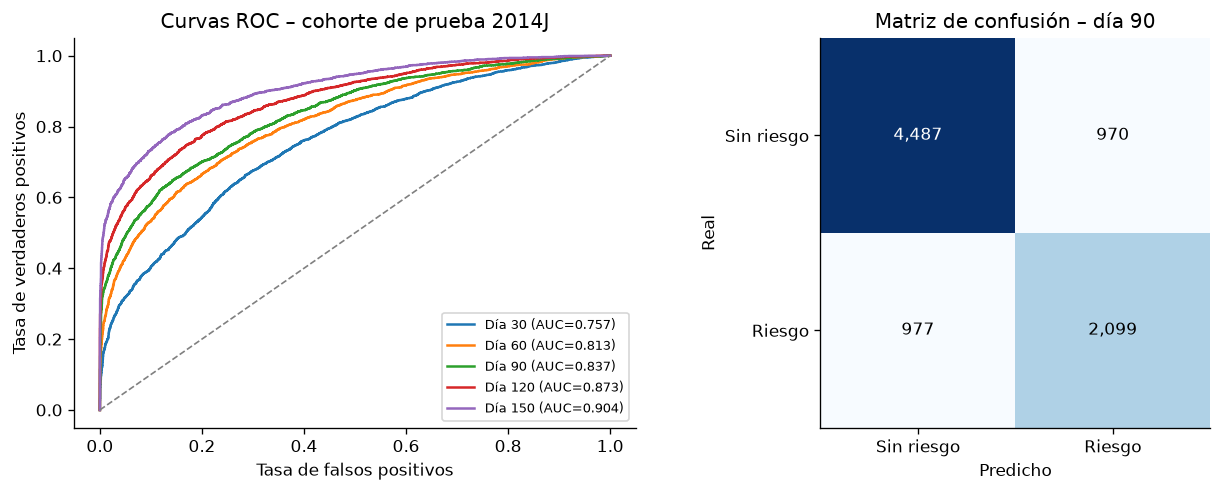

In [3]:
tabla_cortes = pd.DataFrame(metricas_modelo["prueba_por_corte"]).T
tabla_cortes.index.name = "dia_corte"
print(tabla_cortes[["n", "tasa_riesgo_real", "accuracy", "precision", "recall", "f1", "auc"]])
reporte["modelo_por_corte"] = metricas_modelo["prueba_por_corte"]
reporte["cv_auc_entrenamiento"] = metricas_modelo["cv_auc_media"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for corte, g in test.groupby("dia_corte"):
    fpr, tpr, _ = roc_curve(g["riesgo"], g["prob_riesgo"])
    ax[0].plot(fpr, tpr, label=f"Día {corte} (AUC={roc_auc_score(g['riesgo'], g['prob_riesgo']):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos",
          title="Curvas ROC – cohorte de prueba 2014J")
ax[0].legend(fontsize=8)
g90 = test[test["dia_corte"] == CORTE_PRINCIPAL]
cm = confusion_matrix(g90["riesgo"], g90["pred_riesgo"])
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Sin riesgo", "Riesgo"],
          yticklabels=["Sin riesgo", "Riesgo"], xlabel="Predicho", ylabel="Real",
          title=f"Matriz de confusión – día {CORTE_PRINCIPAL}")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "roc_y_confusion.png")

**Calibración de los niveles de riesgo.** Si los niveles están bien construidos, la tasa
real de fracaso/abandono debe crecer de "Bajo" a "Crítico".

              estudiantes  tasa_real_riesgo
nivel_riesgo                               
Bajo                 3319             0.112
Moderado             2145             0.282
Alto                 1484             0.483
Crítico              1585             0.872


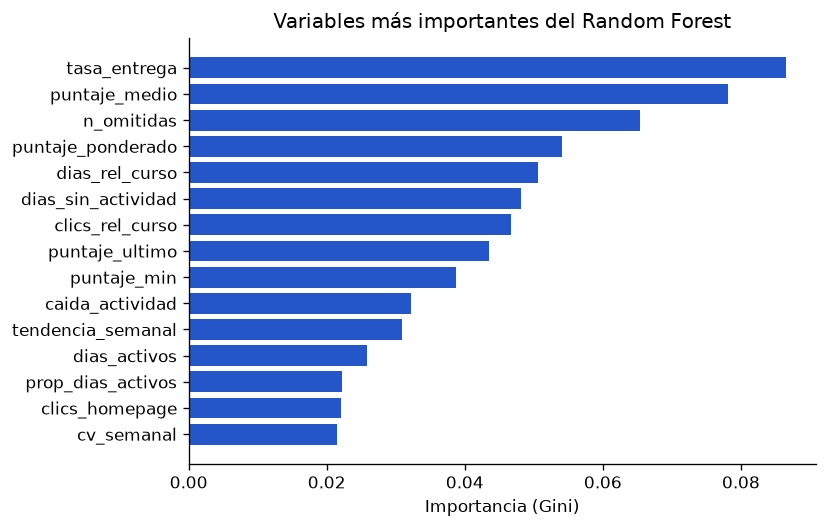

In [4]:
orden_niveles = ["Bajo", "Moderado", "Alto", "Crítico"]
calib = (g90.groupby("nivel_riesgo")["riesgo"].agg(["count", "mean"])
             .reindex(orden_niveles).rename(columns={"count": "estudiantes", "mean": "tasa_real_riesgo"}))
print(calib.round(3))
reporte["calibracion_niveles_dia90"] = calib.round(4).to_dict(orient="index")

imp = pd.read_csv(DIR_SALIDAS / "importancia_variables.csv").head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp["variable"][::-1], imp["importancia"][::-1], color="#2456c9")
ax.set(title="Variables más importantes del Random Forest", xlabel="Importancia (Gini)")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "importancia_variables.png")

## 2. Anticipación: ¿cuántos días antes de darse de baja se emite la alerta?
Para cada estudiante de 2014J que se retiró se busca la primera semana en que el
monitoreo semanal lo marcó en riesgo (probabilidad ≥ 0,5) y se compara con su fecha de baja.

{'retirados_evaluables': 1581, 'pct_detectados_antes_de_la_baja': 0.8387, 'mediana_dias_anticipacion': 68.5, 'pct_detectados_con_2_semanas_o_mas': 0.7451}


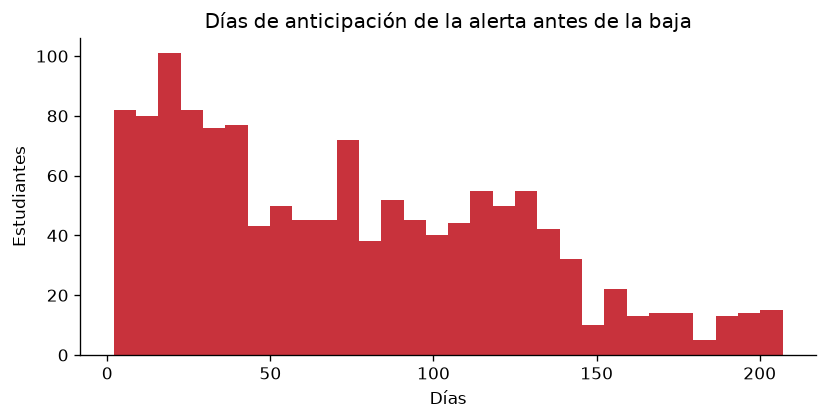

In [5]:
retirados = est[(est["code_presentation"] == PRESENTACION_PRUEBA) & (est["final_result"] == "Withdrawn")
                & est["date_unregistration"].notna()]
primera_alerta = (mon[mon["prob_riesgo"] >= 0.5].assign(dia_alerta=lambda d: d["dia_corte"])
                  .groupby(CLAVE)["dia_alerta"].min())
r = retirados.set_index(CLAVE).join(primera_alerta)
r = r[r["date_unregistration"] > 34]  # solo quienes seguían inscritos cuando el sistema empieza a emitir alertas
r["detectado_antes"] = r["dia_alerta"] < r["date_unregistration"]
anticipacion = (r["date_unregistration"] - r["dia_alerta"])[r["detectado_antes"]]
reporte["anticipacion_abandono"] = {
    "retirados_evaluables": int(len(r)),
    "pct_detectados_antes_de_la_baja": round(float(r["detectado_antes"].mean()), 4),
    "mediana_dias_anticipacion": float(anticipacion.median()),
    "pct_detectados_con_2_semanas_o_mas": round(float((r["date_unregistration"] - r["dia_alerta"] >= 14).mean()), 4),
}
print(reporte["anticipacion_abandono"])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(anticipacion, bins=30, color="#c8323c")
ax.set(title="Días de anticipación de la alerta antes de la baja", xlabel="Días", ylabel="Estudiantes")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "anticipacion_abandono.png")

## 3. Validez de los perfiles diagnosticados
Cada perfil debería asociarse a un desenlace distinto: la *Desconexión* debería anticipar
abandono (Withdrawn) y la *Frustración* / *Bajo rendimiento* reprobación (Fail).

In [6]:
perfil_resultado = pd.crosstab(g90["perfil"], g90["final_result"], normalize="index").round(3)
perfil_resultado["n"] = g90["perfil"].value_counts()
print(perfil_resultado)
reporte["perfiles_vs_resultado_dia90"] = perfil_resultado.to_dict(orient="index")

final_result      Distinction   Fail   Pass  Withdrawn     n
perfil                                                      
Avanzado                0.304  0.059  0.589      0.047  2759
Bajo rendimiento        0.000  0.279  0.581      0.140    43
Desconexión             0.013  0.522  0.222      0.242  1931
En progreso             0.101  0.159  0.646      0.094  2705
Frustración             0.039  0.296  0.467      0.198   514
Procrastinación         0.007  0.358  0.370      0.264   424
Riesgo general          0.013  0.389  0.433      0.166   157


## 4. Acierto de las recomendaciones (evaluación offline)
**4a. Coherencia de nivel**: las misiones deben ser de refuerzo (nivel 1) para perfiles de
riesgo y de reto (nivel 3) para los avanzados.

**4b. Acierto del formato recomendado**: entre los estudiantes en riesgo el día 90, se
compara a quienes *por su cuenta* aumentaron entre el día 90 y el 150 el uso del formato
que el motor les habría recomendado, contra quienes no. Si la recomendación es acertada,
el primer grupo debería terminar mejor. Se ajusta por nivel de riesgo inicial
(estratificación por deciles) para comparar estudiantes comparables. Es una evidencia
observacional, no un experimento controlado.

In [7]:
nivel_mision = {m: int(m.split("-")[1]) for r_ in test["ruta"] for m in r_}
test["nivel_mision_principal"] = test["mision_principal"].map(nivel_mision)
riesgo_perfil = test["perfil"].isin(["Desconexión", "Frustración", "Procrastinación", "Bajo rendimiento"])
coherencia = {
    "pct_perfiles_riesgo_con_mision_nivel_1": round(float((test.loc[riesgo_perfil, "nivel_mision_principal"] == 1).mean()), 4),
    "pct_avanzados_con_mision_nivel_3": round(float((test.loc[test["perfil"] == "Avanzado", "nivel_mision_principal"] == 3).mean()), 4),
    "pct_rutas_con_tema_debil": round(float(test.apply(
        lambda f: any(m.split("-")[0] == {"Programación lineal": "PL", "Transporte y asignación": "TA",
                                          "Gestión de inventarios": "IN", "Teoría de colas": "CO",
                                          "Balanceo de líneas": "BL",
                                          "Planificación de proyectos (PERT/CPM)": "PR",
                                          "Simulación de procesos": "SI"}[f["tema_debil"]] for m in f["ruta"]),
        axis=1).mean()), 4),
}
print(coherencia)

FORM = {"oucontent": ["clics_oucontent"], "quiz": ["clics_quiz"], "forumng": ["clics_forumng"],
        "resource": ["clics_resource", "clics_url", "clics_subpage"]}


def prop_formato(d, f):
    tot = d[[c for cols in FORM.values() for c in cols]].sum(axis=1).replace(0, np.nan)
    return d[FORM[f]].sum(axis=1) / tot


a = test[(test["dia_corte"] == 90) & (test["prob_riesgo"] >= 0.5)].set_index(CLAVE)
b = test[test["dia_corte"] == 150].set_index(CLAVE)
a = a.join(b[[c for cols in FORM.values() for c in cols]], rsuffix="_150", how="inner")
antes = np.array([prop_formato(a, f).loc[k] for k, f in zip(a.index, a["formato_deficit"])])
b150 = a[[c + "_150" for cols in FORM.values() for c in cols]].copy()
b150.columns = [c[:-4] for c in b150.columns]
despues = np.array([prop_formato(b150, f).loc[k] for k, f in zip(a.index, a["formato_deficit"])])
a["siguio_recomendacion"] = (despues - antes) > 0.02
a["exito"] = 1 - a["riesgo"]
a["decil"] = pd.qcut(a["prob_riesgo"], 5, labels=False, duplicates="drop")
estr = a.groupby(["decil", "siguio_recomendacion"])["exito"].mean().unstack()
peso = a.groupby("decil").size() / len(a)
efecto_ajustado = float(((estr[True] - estr[False]) * peso).sum())
tabla = pd.crosstab(a["siguio_recomendacion"], a["exito"])
p_valor = chi2_contingency(tabla)[1]
acierto = {
    "estudiantes_en_riesgo_dia90_aun_activos_dia150": int(len(a)),
    "pct_que_siguio_el_formato_recomendado": round(float(a["siguio_recomendacion"].mean()), 4),
    "tasa_exito_siguio": round(float(a.loc[a["siguio_recomendacion"], "exito"].mean()), 4),
    "tasa_exito_no_siguio": round(float(a.loc[~a["siguio_recomendacion"], "exito"].mean()), 4),
    "diferencia_ajustada_por_riesgo": round(efecto_ajustado, 4),
    "p_valor_chi2": float(f"{p_valor:.3g}"),
}
print(acierto)
reporte["recomendacion"] = {"coherencia": coherencia, "acierto_formato": acierto}

{'pct_perfiles_riesgo_con_mision_nivel_1': 0.8339, 'pct_avanzados_con_mision_nivel_3': 1.0, 'pct_rutas_con_tema_debil': 1.0}


{'estudiantes_en_riesgo_dia90_aun_activos_dia150': 2716, 'pct_que_siguio_el_formato_recomendado': 0.1495, 'tasa_exito_siguio': 0.5394, 'tasa_exito_no_siguio': 0.3251, 'diferencia_ajustada_por_riesgo': 0.0996, 'p_valor_chi2': 1.52e-16}


## 5. Ajuste dinámico de dificultad: coherencia, estabilidad y eficiencia
- **Coherencia**: el nivel final de dificultad debe ser más bajo para quienes realmente
  terminaron en riesgo (AUC del nivel como "predictor de éxito").
- **Estabilidad**: el controlador no debe oscilar (pocos cambios de dirección por estudiante).

{'auc_nivel_final_vs_exito': 0.8097, 'nivel_final_medio_exitosos': 3.831, 'nivel_final_medio_en_riesgo': 2.498, 'pct_semanas_con_ajuste': 0.3297, 'cambio_medio_absoluto_por_semana': 0.0557, 'reversiones_de_direccion_por_estudiante': 0.153, 'pct_semanas_en_zona_de_flujo': 0.5351}


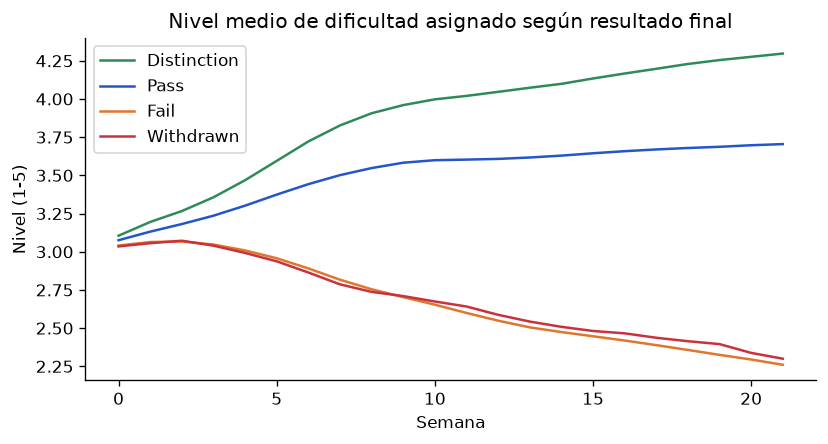

In [8]:
fin = tray.sort_values("semana").groupby(CLAVE).tail(1).merge(est[CLAVE + ["riesgo", "final_result"]], on=CLAVE)
cambios = tray[tray["cambio_nivel"].abs() > 1e-3].copy()
cambios["signo"] = np.sign(cambios["cambio_nivel"])
reversiones = cambios.groupby(CLAVE)["signo"].apply(lambda s: int((s.diff().abs() == 2).sum()))
ajuste = {
    "auc_nivel_final_vs_exito": round(roc_auc_score(1 - fin["riesgo"], fin["nivel"]), 4),
    "nivel_final_medio_exitosos": round(float(fin.loc[fin["riesgo"] == 0, "nivel"].mean()), 3),
    "nivel_final_medio_en_riesgo": round(float(fin.loc[fin["riesgo"] == 1, "nivel"].mean()), 3),
    "pct_semanas_con_ajuste": round(float((tray["cambio_nivel"].abs() > 1e-3).mean()), 4),
    "cambio_medio_absoluto_por_semana": round(float(tray["cambio_nivel"].abs().mean()), 4),
    "reversiones_de_direccion_por_estudiante": round(float(reversiones.reindex(
        pd.MultiIndex.from_frame(fin[CLAVE]), fill_value=0).mean()), 3),
    "pct_semanas_en_zona_de_flujo": round(float(tray["desempeno_suavizado"].between(0.45, 0.75).mean()), 4),
}
print(ajuste)
reporte["ajuste_dificultad"] = ajuste

fig, ax = plt.subplots(figsize=(7, 3.8))
for res, color in [("Distinction", "#2e8b57"), ("Pass", "#2456c9"), ("Fail", "#e0752d"), ("Withdrawn", "#c8323c")]:
    ids = fin.loc[fin["final_result"] == res, CLAVE]
    serie = tray.merge(ids, on=CLAVE).groupby("semana")["nivel"].mean()
    ax.plot(serie.index, serie.values, label=res, color=color)
ax.set(title="Nivel medio de dificultad asignado según resultado final", xlabel="Semana", ylabel="Nivel (1-5)")
ax.legend()
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "dificultad_por_resultado.png")

### Eficiencia computacional

In [9]:
calidad = json.loads((DIR_SALIDAS / "reporte_calidad_datos.json").read_text(encoding="utf-8"))
tiempos_path = DIR_SALIDAS / "tiempos_pipeline.json"
tiempos = json.loads(tiempos_path.read_text()) if tiempos_path.exists() else {}
t = time.time()
_ = mon.groupby("semana")["prob_riesgo"].mean()
eficiencia = {
    "registros_de_clics_procesados": calidad["agregacion_clics"]["registros_originales"],
    "segundos_lectura_y_limpieza": calidad["tiempo_segundos"],
    "segundos_entrenamiento_modelo": metricas_modelo["eficiencia"]["segundos_entrenamiento"],
    "ms_prediccion_por_estudiante": metricas_modelo["eficiencia"]["ms_prediccion_por_estudiante"],
    "tiempos_por_etapa_s": tiempos,
}
print(eficiencia)
reporte["eficiencia"] = eficiencia

{'registros_de_clics_procesados': 10655280, 'segundos_lectura_y_limpieza': 11.7, 'segundos_entrenamiento_modelo': 13.1, 'ms_prediccion_por_estudiante': 0.0083, 'tiempos_por_etapa_s': {'01_preparar_datos.py': 12.6, '02_modelo_riesgo.py': 74.9, '03_motor_recomendacion.py': 8.8, '04_monitoreo_semanal.py': 35.2, '05_ajuste_dificultad.py': 5.1, '06_dashboard.py': 2.7, '07_validacion.py': 13.6, '07b_crear_notebook.py': 1.1, '08_articulo.py': 1.2}}


## Guardado del reporte

In [10]:
(DIR_SALIDAS / "reporte_validacion.json").write_text(json.dumps(reporte, indent=2, ensure_ascii=False, default=str),
                                                      encoding="utf-8")
md =f"""# Reporte de precisión y eficiencia del sistema

Cohorte de prueba: **{PRESENTACION_PRUEBA}** (no usada en el entrenamiento).

## Diagnóstico de riesgo (Random Forest)
| Día de corte | n | Accuracy | Precisión | Recall | F1 | AUC |
|---|---|---|---|---|---|---|
""" + "\n".join(f"| {c} | {v['n']:,} | {v['accuracy']:.3f} | {v['precision']:.3f} | {v['recall']:.3f} | {v['f1']:.3f} | {v['auc']:.3f} |"
                for c, v in reporte["modelo_por_corte"].items()) + f"""

AUC en validación cruzada (entrenamiento): {reporte['cv_auc_entrenamiento']:.3f}.

Calibración de niveles (día {CORTE_PRINCIPAL}), tasa real de fracaso/abandono: """ + ", ".join(
    f"{k}: {v['tasa_real_riesgo']:.0%}" for k, v in reporte["calibracion_niveles_dia90"].items()) + f"""

## Detección anticipada del abandono
- {reporte['anticipacion_abandono']['pct_detectados_antes_de_la_baja']:.1%} de los retirados evaluables recibió una alerta antes de darse de baja.
- Mediana de anticipación: {reporte['anticipacion_abandono']['mediana_dias_anticipacion']:.0f} días.
- {reporte['anticipacion_abandono']['pct_detectados_con_2_semanas_o_mas']:.1%} fue alertado con 2 semanas o más de margen.

## Recomendaciones (rutas adaptativas)
- Perfiles de riesgo con misión de refuerzo (nivel 1): {coherencia['pct_perfiles_riesgo_con_mision_nivel_1']:.1%}
- Avanzados con misión de reto (nivel 3): {coherencia['pct_avanzados_con_mision_nivel_3']:.1%}
- Rutas que incluyen el tema más débil: {coherencia['pct_rutas_con_tema_debil']:.1%}
- Estudiantes en riesgo que aumentaron el formato recomendado: tasa de éxito {acierto['tasa_exito_siguio']:.1%} vs {acierto['tasa_exito_no_siguio']:.1%} (diferencia ajustada por riesgo {acierto['diferencia_ajustada_por_riesgo']:+.1%}, p = {acierto['p_valor_chi2']}).

## Ajuste dinámico de dificultad
- AUC del nivel final como indicador de éxito: {ajuste['auc_nivel_final_vs_exito']:.3f}
- Nivel final medio: exitosos {ajuste['nivel_final_medio_exitosos']:.2f} vs en riesgo {ajuste['nivel_final_medio_en_riesgo']:.2f}
- Cambio medio por semana: {ajuste['cambio_medio_absoluto_por_semana']:.3f} niveles; reversiones de dirección por estudiante: {ajuste['reversiones_de_direccion_por_estudiante']:.2f}
- Semanas dentro de la zona de flujo: {ajuste['pct_semanas_en_zona_de_flujo']:.1%}

## Eficiencia
- {eficiencia['registros_de_clics_procesados']:,} registros de clics procesados en {eficiencia['segundos_lectura_y_limpieza']:.0f} s.
- Entrenamiento: {eficiencia['segundos_entrenamiento_modelo']:.0f} s; predicción: {eficiencia['ms_prediccion_por_estudiante']:.3f} ms por estudiante.

Figuras en `outputs/figuras/`.
"""
(DIR_SALIDAS / "reporte_precision_eficiencia.md").write_text(md, encoding="utf-8")
print("Reporte guardado en outputs/reporte_precision_eficiencia.md")

Reporte guardado en outputs/reporte_precision_eficiencia.md
